# 📊 Khám phá và Phân tích Dữ liệu (EDA) - Bitext Sample Customer Support

**Môn học / Dự án:** TMG301 - Text Mining & NLP  
**Tập dữ liệu:** `Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv` (~27,000 mẫu)  
**Nguồn gốc:** Bitext Customer Support Dataset (Tập dữ liệu mẫu phục vụ xây dựng Chatbot và Trợ lý ảo chăm sóc khách hàng trong thương mại điện tử / dịch vụ).  

---

### 🎯 Mục tiêu thực hiện trong Notebook:
1. **Tổng quan & Kích thước dữ liệu (Dataset Size & Shape):** Kiểm tra số lượng dòng (mẫu), số cột, dung lượng bộ nhớ, giá trị thiếu (Missing values) và trùng lặp (Duplicates).
2. **Tập nhãn cấp cao (`category`) và nhãn chi tiết (`intent`):** Thống kê số lượng nhãn độc nhất, phân cấp danh mục (hierarchical mapping), kiểm tra sự phân bổ giữa các nhóm nghiệp vụ.
3. **Phân bố nhãn & Đánh giá độ cân bằng (Class Distribution & Balance):** Khảo sát phân bố mẫu trên từng category và intent (Min, Max, Mean, Imbalance ratio), biểu đồ cột và biểu đồ phân cấp.
4. **Phân tích Cột `flags` (Linguistic & Noise Variations):** Khám phá các cờ ngôn ngữ học biểu thị dạng câu hỏi, biến thể ngữ cảnh, độ trang trọng, và lỗi chính tả / typo nhằm đánh giá độ phong phú của dữ liệu.
5. **Phân tích Đặc trưng Văn bản (`instruction` & `response`):** Đo lường độ dài ký tự và số lượng từ của cả câu hỏi người dùng và câu phản hồi của bot, phân vị (percentiles) nhằm xác định `max_length` tối ưu cho các mô hình NLP.
6. **Phân tích Thực thể giữ chỗ (Entity Slot Placeholders):** Thống kê các slot dạng `{{...}}` (như `{{Order Number}}`, `{{Website URL}}`) thường dùng trong hội thoại thực tế.
7. **Phân tích Vốn từ vựng & N-grams (Vocabulary & Bigrams):** Đo lường Vocabulary size, Top từ khóa và cụm từ nổi bật trong lĩnh vực chăm sóc khách hàng.
8. **Đề xuất Phân chia Tập dữ liệu (Train / Val / Test Split) & Khuyến nghị Huấn luyện mô hình:** Gợi ý cách phân tầng (Stratified Split) và định hướng mô hình hóa (Intent Classification vs Response Generation / LLM Fine-tuning).

## 1. Thiết lập Thư viện & Cấu hình Hiển thị

In [1]:
import os
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập style hiển thị biểu đồ
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# Cấu hình Pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 140)

print("✅ Đã tải xong các thư viện cần thiết!")

✅ Đã tải xong các thư viện cần thiết!


## 2. Tải Dữ liệu Bitext Customer Support

Đường dẫn được cấu hình linh hoạt để tự động nhận diện file CSV dù bạn chạy notebook từ thư mục gốc dự án hay thư mục con `EDA/`.

In [2]:
# Tự động tìm kiếm file dữ liệu
candidate_paths = [
    Path("datasets/Bitext_Sample_Customer_Support"),
    Path("../datasets/Bitext_Sample_Customer_Support"),
    Path.cwd() / "datasets" / "Bitext_Sample_Customer_Support",
    Path.cwd().parent / "datasets" / "Bitext_Sample_Customer_Support",
]

target_filename = "Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv"
file_path = None

for p in candidate_paths:
    if (p / target_filename).exists():
        file_path = p / target_filename
        break

if file_path is None:
    raise FileNotFoundError(
        f"❌ Không tìm thấy file {target_filename}! Vui lòng kiểm tra lại thư mục datasets/Bitext_Sample_Customer_Support."
    )

print(f"📂 Đang đọc dữ liệu từ: {file_path.resolve()}")
df = pd.read_csv(file_path, encoding="utf-8")
print(f"✅ Đã đọc thành công {len(df):,} dòng dữ liệu!")

📂 Đang đọc dữ liệu từ: D:\FPTU\26FALL\TMG301\project\datasets\Bitext_Sample_Customer_Support\Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv
✅ Đã đọc thành công 26,872 dòng dữ liệu!


## 3. Kích thước & Cấu trúc Tổng quan (Dataset Dimensions & Overview)

Kiểm tra kích thước (số dòng, số cột), kiểu dữ liệu và bộ nhớ chiếm dụng.

In [3]:
num_rows, num_cols = df.shape
mem_usage_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)

summary_dim_df = pd.DataFrame({
    "Chỉ số": ["Tổng số dòng (Mẫu câu)", "Tổng số cột (Thuộc tính)", "Dung lượng RAM chiếm dụng", "Tên các cột"],
    "Giá trị": [
        f"{num_rows:,} mẫu",
        f"{num_cols} cột",
        f"{mem_usage_mb:.2f} MB",
        ", ".join(df.columns.tolist())
    ]
})

print("=== BẢNG TỔNG QUAN KÍCH THƯỚC DỮ LIỆU ===")
display(summary_dim_df)

print("\n--- Thông tin kiểu dữ liệu và bộ nhớ (df.info()) ---")
df.info()

=== BẢNG TỔNG QUAN KÍCH THƯỚC DỮ LIỆU ===


,Chỉ số,Giá trị
0,Tổng số dòng (Mẫu câu),"26,872 mẫu"
1,Tổng số cột (Thuộc tính),5 cột
2,Dung lượng RAM chiếm dụng,25.57 MB
3,Tên các cột,"flags, instruction, category, intent, response"



--- Thông tin kiểu dữ liệu và bộ nhớ (df.info()) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB


### Xem trước các dòng mẫu đầu tiên và ngẫu nhiên

In [4]:
print("--- 3 Dòng đầu tiên của tập dữ liệu ---")
display(df.head(3))

print("\n--- 3 Dòng lấy mẫu ngẫu nhiên (Random Sample) ---")
display(df.sample(3, random_state=42))

--- 3 Dòng đầu tiên của tập dữ liệu ---


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,"I've understood you have a question regarding canceling order {{Order Number}}, and I'm here to provide you with the information you nee..."
1,BQZ,i have a question about cancelling oorder {{Order Number}},ORDER,cancel_order,I've been informed that you have a question about canceling order {{Order Number}}. I'm here to assist you! Please go ahead and let me k...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance with canceling your purchase with the purchase number {{Order Number}}. I apologize for any i...



--- 3 Dòng lấy mẫu ngẫu nhiên (Random Sample) ---


,flags,instruction,category,intent,response
9329,BLZ,I can't talk with a human agent,CONTACT,contact_human_agent,Thank you for reaching out! I'm sorry to hear that you're facing difficulties in connecting with a human agent. Please rest assured that...
4160,BLMZ,I have got to locate hte bills from {{Person Name}},INVOICE,check_invoice,I'll get right on it! I understand your need to locate the bills associated with {{Person Name}}. To assist you in finding the relevant ...
18500,BCELM,"I cannot pay, help me to inform of a problem with payments",PAYMENT,payment_issue,I apologize for the inconvenience caused by the payment issue you're experiencing. I understand how frustrating it can be when you encou...


## 4. Kiểm tra Giá trị Thiếu (Missing Values) & Trùng lặp (Duplicates)

Kiểm tra tính toàn vẹn của dữ liệu:
- Có trường nào bị thiếu giá trị (Null / NaN) không?
- Có các bản ghi trùng lặp hoàn toàn trên toàn bộ thuộc tính không?
- Có sự lặp lại của câu hỏi khách hàng (`instruction`) hoặc câu trả lời (`response`) không?

In [5]:
# 1. Kiểm tra Missing Values
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    "Số lượng Missing": missing_counts,
    "Tỷ lệ Missing (%)": missing_percent.map("{:.2f}%".format)
})

print("=== KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES) ===")
display(missing_df)

# 2. Kiểm tra Duplicates
dup_all = df.duplicated().sum()
dup_instruction = df.duplicated(subset=["instruction"]).sum()
dup_response = df.duplicated(subset=["response"]).sum()
dup_intent_inst = df.duplicated(subset=["instruction", "intent"]).sum()

print("\n=== KIỂM TRA BẢN GHI TRÙNG LẶP (DUPLICATES) ===")
print(f"- Số bản ghi trùng hoàn toàn (tất cả các cột): {dup_all} ({dup_all / len(df) * 100:.2f}%)")
print(f"- Số câu hỏi (`instruction`) bị trùng lặp:      {dup_instruction:,} ({dup_instruction / len(df) * 100:.2f}%)")
print(f"- Số câu trả lời (`response`) bị trùng lặp:      {dup_response:,} ({dup_response / len(df) * 100:.2f}%)")
print(f"- Số cặp (instruction, intent) bị trùng:         {dup_intent_inst:,}")
print(f"- Số câu hỏi duy nhất (Unique instructions):     {df['instruction'].nunique():,}")
print(f"- Số câu trả lời duy nhất (Unique responses):   {df['response'].nunique():,}")

=== KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES) ===


,Số lượng Missing,Tỷ lệ Missing (%)
flags,0,0.00%
instruction,0,0.00%
category,0,0.00%
intent,0,0.00%
response,0,0.00%



=== KIỂM TRA BẢN GHI TRÙNG LẶP (DUPLICATES) ===
- Số bản ghi trùng hoàn toàn (tất cả các cột): 0 (0.00%)
- Số câu hỏi (`instruction`) bị trùng lặp:      2,237 (8.32%)
- Số câu trả lời (`response`) bị trùng lặp:      2 (0.01%)
- Số cặp (instruction, intent) bị trùng:         2,237
- Số câu hỏi duy nhất (Unique instructions):     24,635
- Số câu trả lời duy nhất (Unique responses):   26,870


## 5. Khám phá Tập nhãn Phân cấp (`category` & `intent`)

Trong tập dữ liệu Bitext Customer Support, nhãn được tổ chức theo mô hình phân cấp 2 tầng:
1. **`category`**: Danh mục cấp cao (Macro Domain - ví dụ: `ORDER`, `ACCOUNT`, `REFUND`, `INVOICE`,...)
2. **`intent`**: Ý định chi tiết (Granular Intent - ví dụ: `cancel_order`, `track_order`, `change_shipping_address`,...)

Ta sẽ kiểm tra số lượng nhãn của từng tầng và mối liên hệ phân cấp giữa chúng.

In [6]:
categories = sorted(df["category"].unique())
intents = sorted(df["intent"].unique())

print(f"✓ Số lượng danh mục cấp cao (`category`): {len(categories)} danh mục")
print(f"✓ Số lượng ý định chi tiết (`intent`):      {len(intents)} intents")

# Ánh xạ giữa category và các intents trực thuộc
cat_intent_map = df.groupby("category")["intent"].unique().to_dict()

cat_intent_summary = []
for cat, int_list in cat_intent_map.items():
    cat_intent_summary.append({
        "Category": cat,
        "Số lượng Intent": len(int_list),
        "Danh sách các Intent trực thuộc": ", ".join(sorted(int_list))
    })

cat_intent_df = pd.DataFrame(cat_intent_summary)
print("\n=== BẢNG PHÂN CẤP CATEGORY -> INTENTS TRỰC THUỘC ===")
display(cat_intent_df)

✓ Số lượng danh mục cấp cao (`category`): 11 danh mục
✓ Số lượng ý định chi tiết (`intent`):      27 intents

=== BẢNG PHÂN CẤP CATEGORY -> INTENTS TRỰC THUỘC ===


,Category,Số lượng Intent,Danh sách các Intent trực thuộc
0,ACCOUNT,6,"create_account, delete_account, edit_account, recover_password, registration_problems, switch_account"
1,CANCEL,1,check_cancellation_fee
2,CONTACT,2,"contact_customer_service, contact_human_agent"
3,DELIVERY,2,"delivery_options, delivery_period"
4,FEEDBACK,2,"complaint, review"
5,INVOICE,2,"check_invoice, get_invoice"
6,ORDER,4,"cancel_order, change_order, place_order, track_order"
7,PAYMENT,2,"check_payment_methods, payment_issue"
8,REFUND,3,"check_refund_policy, get_refund, track_refund"
9,SHIPPING,2,"change_shipping_address, set_up_shipping_address"


## 6. Phân tích Phân bố Nhãn (Class Distribution & Balance)

Khảo sát:
1. Số lượng mẫu của từng `category`.
2. Số lượng mẫu của từng `intent`.
3. Đánh giá mức độ cân bằng dữ liệu (Class balance / Imbalance).

In [7]:
# Đếm số lượng mẫu theo Category
cat_counts = df["category"].value_counts()
cat_dist_df = pd.DataFrame({
    "Số lượng mẫu": cat_counts,
    "Tỷ lệ (%)": (cat_counts / len(df) * 100).map("{:.2f}%".format)
})

# Đếm số lượng mẫu theo Intent
intent_counts = df["intent"].value_counts()
intent_stats_df = pd.DataFrame({
    "Chỉ số thống kê": [
        "Tổng số intents",
        "Số mẫu ít nhất (Min)",
        "Số mẫu nhiều nhất (Max)",
        "Trung bình (Mean)",
        "Trung vị (Median)",
        "Độ lệch chuẩn (Std)",
        "Hệ số mất cân bằng (Max / Min)"
    ],
    "Giá trị phân bố Intent": [
        len(intent_counts),
        intent_counts.min(),
        intent_counts.max(),
        f"{intent_counts.mean():.2f}",
        f"{intent_counts.median():.2f}",
        f"{intent_counts.std():.2f}",
        f"{intent_counts.max() / intent_counts.min():.2f}x"
    ]
})

print("=== PHÂN BỐ CÁC DANH MỤC CẤP CAO (CATEGORIES) ===")
display(cat_dist_df)

print("\n=== THỐNG KÊ PHÂN BỐ CÁC Ý ĐỊNH (INTENTS) ===")
display(intent_stats_df)

=== PHÂN BỐ CÁC DANH MỤC CẤP CAO (CATEGORIES) ===


,Số lượng mẫu,Tỷ lệ (%)
category,,
ACCOUNT,5986,22.28%
ORDER,3988,14.84%
REFUND,2992,11.13%
CONTACT,1999,7.44%
INVOICE,1999,7.44%
PAYMENT,1998,7.44%
FEEDBACK,1997,7.43%
DELIVERY,1994,7.42%
SHIPPING,1970,7.33%



=== THỐNG KÊ PHÂN BỐ CÁC Ý ĐỊNH (INTENTS) ===


,Chỉ số thống kê,Giá trị phân bố Intent
0,Tổng số intents,27
1,Số mẫu ít nhất (Min),950
2,Số mẫu nhiều nhất (Max),1000
3,Trung bình (Mean),995.26
4,Trung vị (Median),998.00
5,Độ lệch chuẩn (Std),10.37
6,Hệ số mất cân bằng (Max / Min),1.05x


### Trực quan hóa Phân bố Category: Biểu đồ Cột & Biểu đồ Tròn

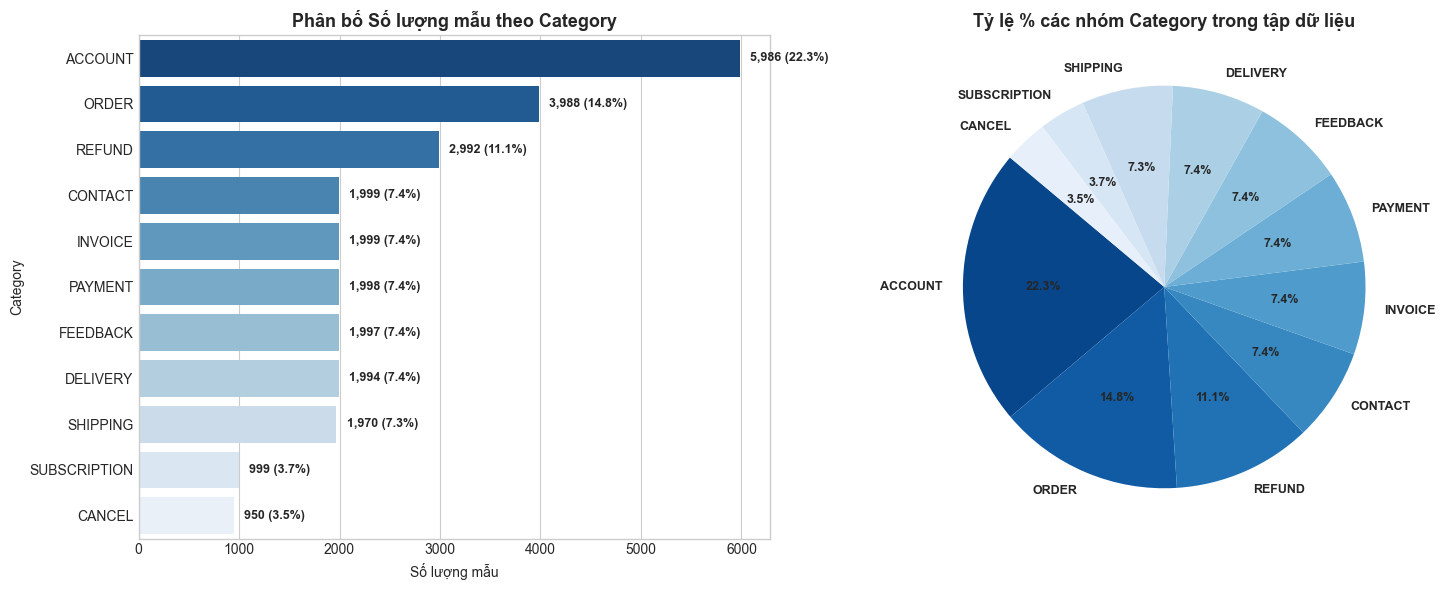

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Bar Chart phân bố Category
palette = sns.color_palette("Blues_r", len(cat_counts))
sns.barplot(x=cat_counts.values, y=cat_counts.index, hue=cat_counts.index, palette=palette, ax=axes[0], legend=False)
axes[0].set_title("Phân bố Số lượng mẫu theo Category", fontsize=13)
axes[0].set_xlabel("Số lượng mẫu")
axes[0].set_ylabel("Category")
for i, v in enumerate(cat_counts.values):
    axes[0].text(v + 100, i, f"{v:,} ({v/len(df)*100:.1f}%)", va="center", fontsize=9, weight="bold")

# 2. Pie Chart tỷ lệ phần trăm Category
axes[1].pie(
    cat_counts.values,
    labels=cat_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=palette,
    textprops={"fontsize": 9, "weight": "bold"}
)
axes[1].set_title("Tỷ lệ % các nhóm Category trong tập dữ liệu", fontsize=13)

plt.tight_layout()
plt.show()

### Trực quan hóa Phân bố Toàn bộ các Ý định (Intent Distribution)

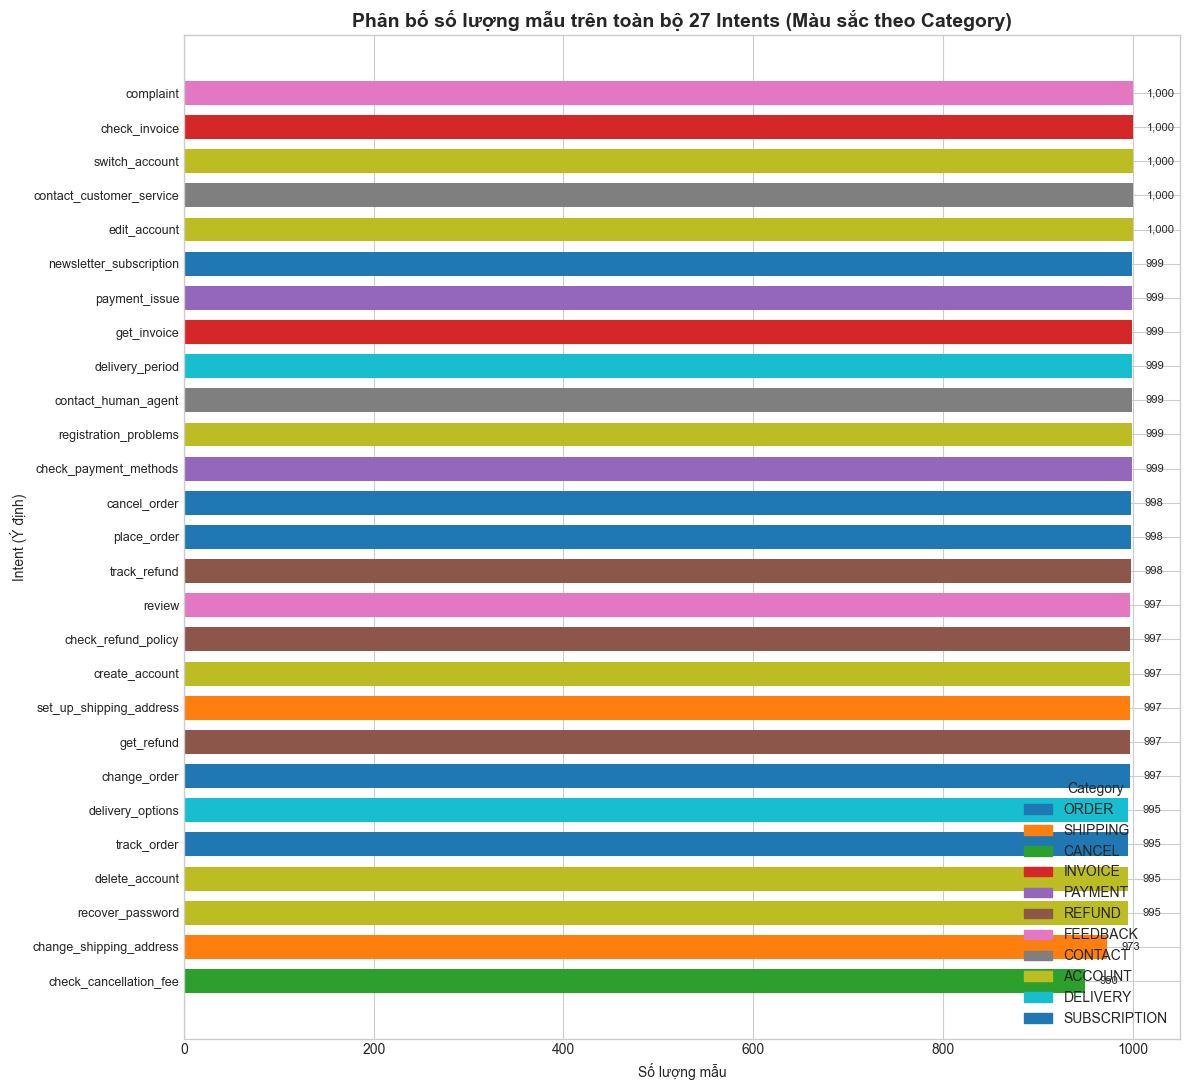

In [9]:
plt.figure(figsize=(12, 11))

# Lấy màu sắc tương ứng theo Category của từng intent
intent_cat_map = df.drop_duplicates(subset=["intent"]).set_index("intent")["category"].to_dict()
sorted_intents = intent_counts.sort_values(ascending=True)

# Ánh xạ bảng màu riêng cho từng Category để trực quan hóa rõ ràng
unique_cats = list(df["category"].unique())
cat_colors = dict(zip(unique_cats, sns.color_palette("tab10", len(unique_cats))))
bar_colors = [cat_colors[intent_cat_map[it]] for it in sorted_intents.index]

y_pos = np.arange(len(sorted_intents))
plt.barh(y_pos, sorted_intents.values, color=bar_colors, height=0.7)
plt.yticks(y_pos, sorted_intents.index, fontsize=9)
plt.xlabel("Số lượng mẫu")
plt.ylabel("Intent (Ý định)")
plt.title(f"Phân bố số lượng mẫu trên toàn bộ {len(sorted_intents)} Intents (Màu sắc theo Category)", fontsize=14, weight="bold")

# Thêm giá trị số mẫu bên cạnh mỗi thanh
for i, v in enumerate(sorted_intents.values):
    plt.text(v + 15, i, f"{v:,}", va="center", fontsize=8)

# Legend Category
handles = [plt.Rectangle((0,0),1,1, color=cat_colors[cat]) for cat in unique_cats]
plt.legend(handles, unique_cats, loc="lower right", title="Category")
plt.tight_layout()
plt.show()

## 7. Phân tích Cột `flags` (Linguistic & Noise Variations)

Tập dữ liệu Bitext cung cấp cột `flags` nhằm phân loại các đặc trưng ngôn ngữ và biến thể của câu hỏi khách hàng:
- `B` (Basic / Declarative / Imperative): Câu mệnh lệnh hoặc trần thuật cơ bản.
- `Q` (Question): Câu hỏi (có từ nghi vấn hoặc dấu hỏi chấm).
- `L` (Polite / Colloquial / Long): Lời nói lịch sự, mở đầu dài dòng hoặc mang sắc thái thân mật.
- `Z` (Spelling / Typo error): Câu có chứa lỗi chính tả cố tình được đưa vào để kiểm tra khả năng chịu lỗi (noise robustness) của mô hình NLP.
- Các tổ hợp như `BQ`, `BLQZ`, `BZ`, `QZ`...

Hãy cùng thống kê tần suất xuất hiện của các cờ này.

=== THỐNG KÊ CÁC CỜ ĐƠN LẺ TRONG DỮ LIỆU ===


,Ký tự Flag,Số mẫu chứa Flag,Tỷ lệ (%)
0,B,26872,100.00%
1,C,2646,9.85%
2,E,1882,7.00%
3,I,7839,29.17%
4,K,2227,8.29%
5,L,24115,89.74%
6,M,4920,18.31%
7,N,463,1.72%
8,P,1329,4.95%
9,Q,8968,33.37%


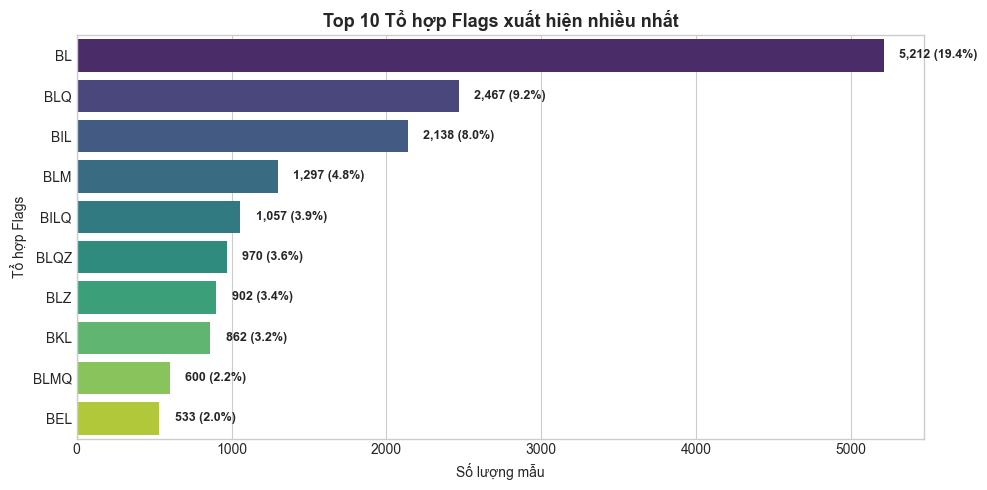

In [10]:
# Tần suất các tổ hợp flags
flag_combos = df["flags"].value_counts()

# Đếm sự hiện diện của từng ký tự cờ đơn lẻ
flag_individual = {}
all_chars = set("".join(df["flags"].dropna().unique()))
for char in sorted(all_chars):
    flag_individual[char] = df["flags"].str.contains(char, na=False).sum()

flag_individual_df = pd.DataFrame({
    "Ký tự Flag": list(flag_individual.keys()),
    "Số mẫu chứa Flag": list(flag_individual.values()),
    "Tỷ lệ (%)": [f"{v / len(df) * 100:.2f}%" for v in flag_individual.values()]
})

print("=== THỐNG KÊ CÁC CỜ ĐƠN LẺ TRONG DỮ LIỆU ===")
display(flag_individual_df)

# Biểu đồ Top các tổ hợp flags phổ biến nhất
plt.figure(figsize=(10, 5))
top_flags = flag_combos.head(10)
sns.barplot(x=top_flags.values, y=top_flags.index, hue=top_flags.index, palette="viridis", legend=False)
plt.title("Top 10 Tổ hợp Flags xuất hiện nhiều nhất", fontsize=13)
plt.xlabel("Số lượng mẫu")
plt.ylabel("Tổ hợp Flags")
for i, v in enumerate(top_flags.values):
    plt.text(v + 100, i, f"{v:,} ({v / len(df) * 100:.1f}%)", va="center", fontsize=9, weight="bold")
plt.tight_layout()
plt.show()

## 8. Phân tích Đặc trưng Văn bản (`instruction` & `response`)

Khảo sát độ dài văn bản của:
1. **`instruction`** (Câu hỏi/yêu cầu của khách hàng): Dùng để xác định `max_seq_length` khi huấn luyện mô hình phân loại intent (BERT, RoBERTa).
2. **`response`** (Câu phản hồi của nhân viên/bot chăm sóc khách hàng): Dùng để xác định độ dài token tối đa khi fine-tuning mô hình sinh văn bản (LLM, T5, LLaMA, GPT).

In [11]:
# Tính độ dài ký tự và số lượng từ
df["inst_char_len"] = df["instruction"].astype(str).apply(len)
df["inst_word_count"] = df["instruction"].astype(str).apply(lambda x: len(x.split()))

df["resp_char_len"] = df["response"].astype(str).apply(len)
df["resp_word_count"] = df["response"].astype(str).apply(lambda x: len(x.split()))

# Bảng phân vị chi tiết
length_stats = pd.DataFrame({
    "Chỉ số phân vị": [
        "Nhỏ nhất (Min)",
        "Trung bình (Mean)",
        "Độ lệch chuẩn (Std)",
        "Trung vị (Median / 50th)",
        "75th Percentile",
        "90th Percentile",
        "95th Percentile",
        "99th Percentile",
        "Lớn nhất (Max)"
    ],
    "Instruction - Ký tự": [
        df["inst_char_len"].min(),
        f"{df['inst_char_len'].mean():.1f}",
        f"{df['inst_char_len'].std():.1f}",
        df["inst_char_len"].median(),
        df["inst_char_len"].quantile(0.75),
        df["inst_char_len"].quantile(0.90),
        df["inst_char_len"].quantile(0.95),
        df["inst_char_len"].quantile(0.99),
        df["inst_char_len"].max()
    ],
    "Instruction - Số từ": [
        df["inst_word_count"].min(),
        f"{df['inst_word_count'].mean():.1f}",
        f"{df['inst_word_count'].std():.1f}",
        df["inst_word_count"].median(),
        df["inst_word_count"].quantile(0.75),
        df["inst_word_count"].quantile(0.90),
        df["inst_word_count"].quantile(0.95),
        df["inst_word_count"].quantile(0.99),
        df["inst_word_count"].max()
    ],
    "Response - Ký tự": [
        df["resp_char_len"].min(),
        f"{df['resp_char_len'].mean():.1f}",
        f"{df['resp_char_len'].std():.1f}",
        df["resp_char_len"].median(),
        df["resp_char_len"].quantile(0.75),
        df["resp_char_len"].quantile(0.90),
        df["resp_char_len"].quantile(0.95),
        df["resp_char_len"].quantile(0.99),
        df["resp_char_len"].max()
    ],
    "Response - Số từ": [
        df["resp_word_count"].min(),
        f"{df['resp_word_count'].mean():.1f}",
        f"{df['resp_word_count'].std():.1f}",
        df["resp_word_count"].median(),
        df["resp_word_count"].quantile(0.75),
        df["resp_word_count"].quantile(0.90),
        df["resp_word_count"].quantile(0.95),
        df["resp_word_count"].quantile(0.99),
        df["resp_word_count"].max()
    ]
})

print("=== BẢNG THỐNG KÊ PHÂN PHỐI ĐỘ DÀI VĂN BẢN ===")
display(length_stats)

=== BẢNG THỐNG KÊ PHÂN PHỐI ĐỘ DÀI VĂN BẢN ===


,Chỉ số phân vị,Instruction - Ký tự,Instruction - Số từ,Response - Ký tự,Response - Số từ
0,Nhỏ nhất (Min),6,1,57,9
1,Trung bình (Mean),46.9,8.7,634.1,104.8
2,Độ lệch chuẩn (Std),10.9,2.6,331.6,53.0
3,Trung vị (Median / 50th),48.0,9.0,540.0,90.0
4,75th Percentile,55.0,11.0,753.0,124.0
5,90th Percentile,59.0,12.0,1059.0,173.0
6,95th Percentile,61.0,13.0,1295.0,206.0
7,99th Percentile,71.0,14.0,1837.0,300.0
8,Lớn nhất (Max),92,16,2472,402


### Trực quan hóa Phân phối Độ dài: Histogram, Mật độ KDE và Boxplot

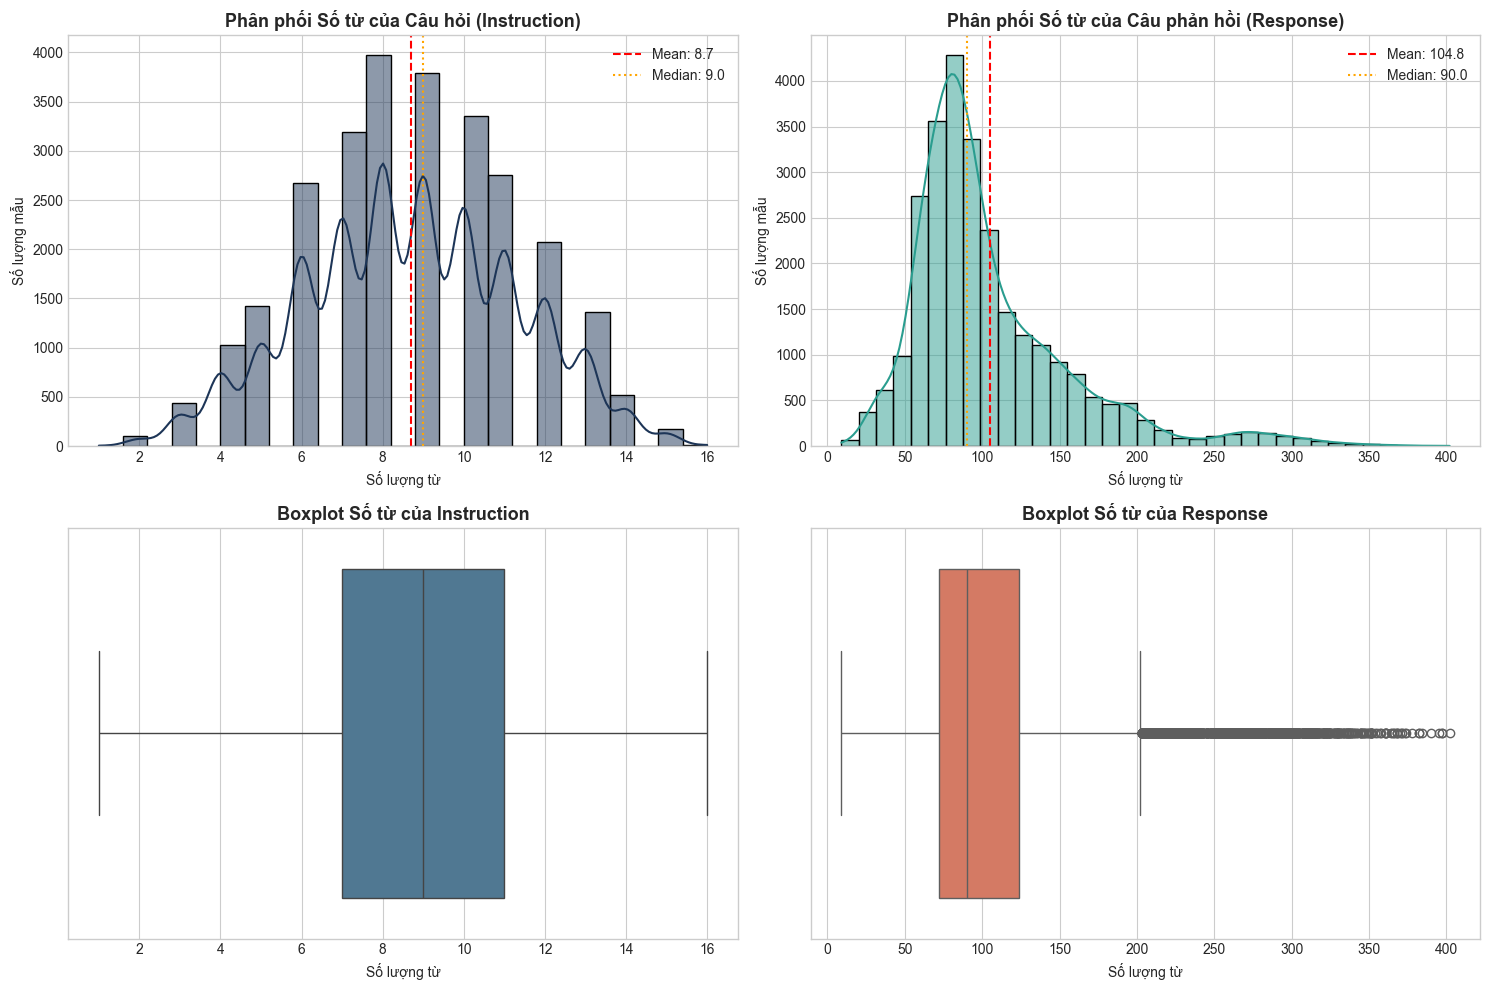

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Phân phối Số từ của Instruction
sns.histplot(df["inst_word_count"], kde=True, ax=axes[0, 0], color="#1d3557", bins=25)
axes[0, 0].axvline(df["inst_word_count"].mean(), color="red", linestyle="--", label=f"Mean: {df['inst_word_count'].mean():.1f}")
axes[0, 0].axvline(df["inst_word_count"].median(), color="orange", linestyle=":", label=f"Median: {df['inst_word_count'].median():.1f}")
axes[0, 0].set_title("Phân phối Số từ của Câu hỏi (Instruction)")
axes[0, 0].set_xlabel("Số lượng từ")
axes[0, 0].set_ylabel("Số lượng mẫu")
axes[0, 0].legend()

# 2. Phân phối Số từ của Response
sns.histplot(df["resp_word_count"], kde=True, ax=axes[0, 1], color="#2a9d8f", bins=35)
axes[0, 1].axvline(df["resp_word_count"].mean(), color="red", linestyle="--", label=f"Mean: {df['resp_word_count'].mean():.1f}")
axes[0, 1].axvline(df["resp_word_count"].median(), color="orange", linestyle=":", label=f"Median: {df['resp_word_count'].median():.1f}")
axes[0, 1].set_title("Phân phối Số từ của Câu phản hồi (Response)")
axes[0, 1].set_xlabel("Số lượng từ")
axes[0, 1].set_ylabel("Số lượng mẫu")
axes[0, 1].legend()

# 3. Boxplot Số từ của Instruction
sns.boxplot(x=df["inst_word_count"], ax=axes[1, 0], color="#457b9d")
axes[1, 0].set_title("Boxplot Số từ của Instruction")
axes[1, 0].set_xlabel("Số lượng từ")

# 4. Boxplot Số từ của Response
sns.boxplot(x=df["resp_word_count"], ax=axes[1, 1], color="#e76f51")
axes[1, 1].set_title("Boxplot Số từ của Response")
axes[1, 1].set_xlabel("Số lượng từ")

plt.tight_layout()
plt.show()

## 9. Phân tích Thực thể Giữ chỗ (Entity Slot Placeholders)

Bộ dữ liệu Bitext được thiết kế sẵn các slot/placeholder dạng `{{Tên thực thể}}` (ví dụ: `{{Order Number}}`, `{{Customer Support Phone Number}}`, `{{Website URL}}`).  
Khi triển khai thực tế vào hệ thống Chatbot/RAG:
- Hệ thống sẽ trích xuất thực thể (NER / Slot Filling) từ người dùng hoặc điền thông tin động (dynamic templating) vào câu trả lời.
Hãy cùng xem các slot nào xuất hiện nhiều nhất.

✓ Số lượng slots duy nhất trong câu hỏi (Instruction): 9
✓ Số lượng slots duy nhất trong câu trả lời (Response): 391


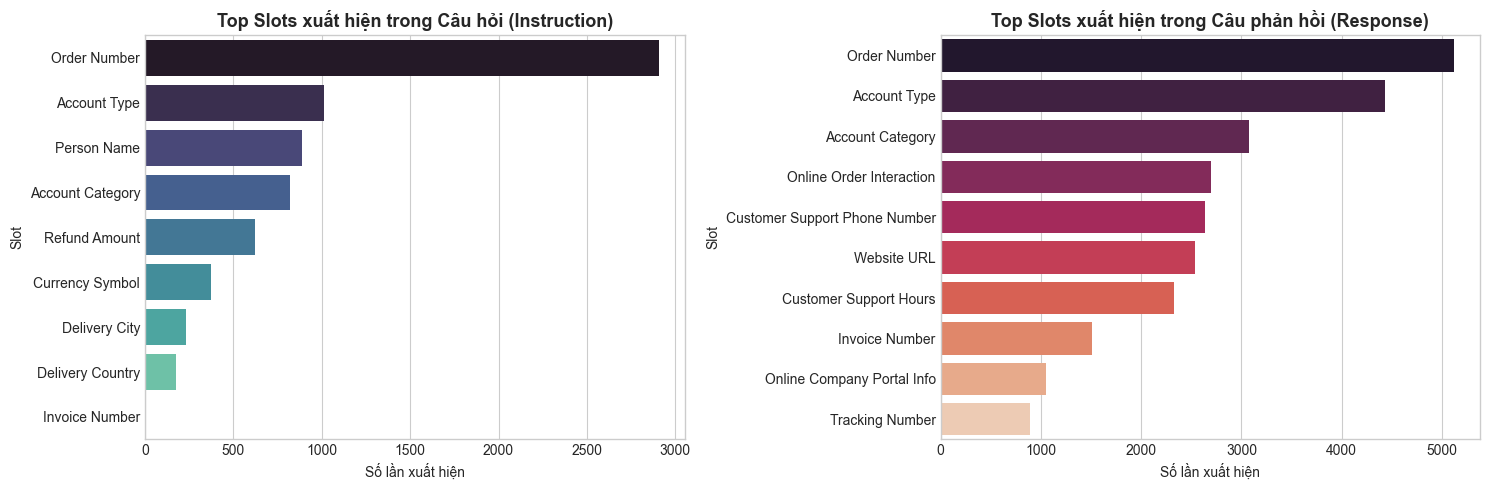

In [13]:
slot_regex = r"\{\{([^}]+)\}\}"

inst_slots = [slot for text in df["instruction"].dropna() for slot in re.findall(slot_regex, text)]
resp_slots = [slot for text in df["response"].dropna() for slot in re.findall(slot_regex, text)]

inst_slot_counts = Counter(inst_slots)
resp_slot_counts = Counter(resp_slots)

print(f"✓ Số lượng slots duy nhất trong câu hỏi (Instruction): {len(inst_slot_counts)}")
print(f"✓ Số lượng slots duy nhất trong câu trả lời (Response): {len(resp_slot_counts)}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Top Slots trong Instruction
top_inst_slots = pd.DataFrame(inst_slot_counts.most_common(10), columns=["Slot", "Count"])
if len(top_inst_slots) > 0:
    sns.barplot(x="Count", y="Slot", hue="Slot", data=top_inst_slots, ax=axes[0], palette="mako", legend=False)
    axes[0].set_title("Top Slots xuất hiện trong Câu hỏi (Instruction)")
    axes[0].set_xlabel("Số lần xuất hiện")

# Top Slots trong Response
top_resp_slots = pd.DataFrame(resp_slot_counts.most_common(10), columns=["Slot", "Count"])
sns.barplot(x="Count", y="Slot", hue="Slot", data=top_resp_slots, ax=axes[1], palette="rocket", legend=False)
axes[1].set_title("Top Slots xuất hiện trong Câu phản hồi (Response)")
axes[1].set_xlabel("Số lần xuất hiện")

plt.tight_layout()
plt.show()

## 10. Phân tích Vốn từ vựng & N-grams (Vocabulary & Bigrams)

Khảo sát các từ khóa và cụm 2 từ (Bigrams) xuất hiện nhiều nhất trong câu hỏi của khách hàng (sau khi loại bỏ Stopwords tiếng Anh).

- Tổng số Tokens trong toàn bộ Instructions: 202,297
- Kích thước Vốn từ vựng duy nhất (Vocabulary Size): 2,830 từ


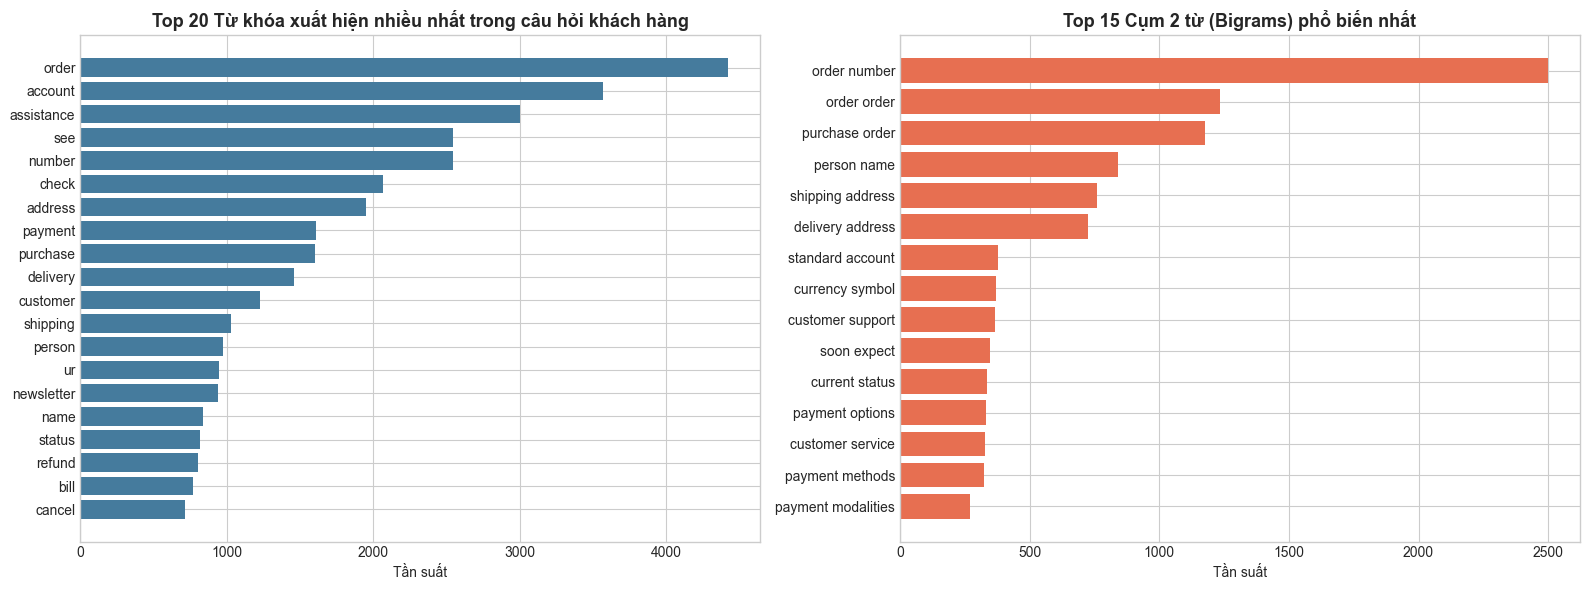

In [14]:
def tokenize_clean(text):
    # Loại bỏ placeholder dạng {{...}}
    text_clean = re.sub(r"\{\{[^}]+\}\} ", " ", text)
    return re.findall(r"\b[a-zA-Z]{2,}\b", text_clean.lower())

stopwords = set([
    "i", "me", "my", "myself", "we", "our", "ours", "ourselves", "you", "your", "yours", 
    "he", "him", "his", "she", "her", "it", "its", "they", "them", "their", "what", "which", 
    "who", "whom", "this", "that", "these", "those", "am", "is", "are", "was", "were", "be", 
    "been", "being", "have", "has", "had", "having", "do", "does", "did", "doing", "a", "an", 
    "the", "and", "but", "if", "or", "because", "as", "until", "while", "of", "at", "by", "for", 
    "with", "about", "against", "between", "into", "through", "during", "before", "after", "above", 
    "below", "to", "from", "up", "down", "in", "out", "on", "off", "over", "under", "again", 
    "further", "then", "once", "here", "there", "when", "where", "why", "how", "all", "any", 
    "both", "each", "few", "more", "most", "other", "some", "such", "no", "nor", "not", "only", 
    "own", "same", "so", "than", "too", "very", "s", "t", "can", "will", "just", "don", "should", 
    "now", "d", "ll", "m", "o", "re", "ve", "y", "need", "want", "like", "help", "please",
    "would", "could", "get", "know"
])

# Tokens của toàn bộ instruction
all_inst_tokens = [tok for text in df["instruction"].dropna() for tok in tokenize_clean(text)]
inst_vocab = set(all_inst_tokens)

print(f"- Tổng số Tokens trong toàn bộ Instructions: {len(all_inst_tokens):,}")
print(f"- Kích thước Vốn từ vựng duy nhất (Vocabulary Size): {len(inst_vocab):,} từ")

# Lọc Stopwords
filtered_words = [tok for tok in all_inst_tokens if tok not in stopwords]
top_20_words = Counter(filtered_words).most_common(20)

# Tạo Bigrams
bigrams = []
for text in df["instruction"].dropna():
    tokens = [tok for tok in tokenize_clean(text) if tok not in stopwords]
    for i in range(len(tokens) - 1):
        bigrams.append(f"{tokens[i]} {tokens[i+1]}")

top_15_bigrams = Counter(bigrams).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 20 từ đơn
top_words_df = pd.DataFrame(top_20_words, columns=["Word", "Frequency"]).sort_values("Frequency")
axes[0].barh(top_words_df["Word"], top_words_df["Frequency"], color="#457b9d")
axes[0].set_title("Top 20 Từ khóa xuất hiện nhiều nhất trong câu hỏi khách hàng")
axes[0].set_xlabel("Tần suất")

# Top 15 Bigrams
top_bigrams_df = pd.DataFrame(top_15_bigrams, columns=["Bigram", "Frequency"]).sort_values("Frequency")
axes[1].barh(top_bigrams_df["Bigram"], top_bigrams_df["Frequency"], color="#e76f51")
axes[1].set_title("Top 15 Cụm 2 từ (Bigrams) phổ biến nhất")
axes[1].set_xlabel("Tần suất")

plt.tight_layout()
plt.show()

## 11. Đề xuất Chiến lược Phân chia Dữ liệu (Train / Validation / Test Split)

Hiện tại dữ liệu nằm trọn vẹn trong một file duy nhất gồm ~27K mẫu.  
Để huấn luyện và đánh giá mô hình một cách khách quan, ta cần phân chia dữ liệu theo phương pháp **Stratified Sampling** (Phân tầng theo nhãn `intent`):
- Tỷ lệ khuyến nghị: **80% Train** / **10% Validation** / **10% Test** (hoặc 70% / 15% / 15%).
- Việc phân tầng đảm bảo cả 27 intents đều có tỷ lệ xuất hiện đồng đều và công bằng ở cả 3 tập.

In [15]:
# Code minh họa cách phân chia Stratified Split chuẩn bằng scikit-learn
try:
    from sklearn.model_selection import train_test_split

    # Tách 80% Train và 20% phần còn lại (Temp)
    train_set, temp_set = train_test_split(
        df, test_size=0.20, random_state=42, stratify=df["intent"]
    )

    # Tách Temp thành 10% Val và 10% Test
    val_set, test_set = train_test_split(
        temp_set, test_size=0.50, random_state=42, stratify=temp_set["intent"]
    )

    split_summary = pd.DataFrame({
        "Tập dữ liệu": ["Train", "Validation", "Test", "Tổng cộng"],
        "Số mẫu (Rows)": [len(train_set), len(val_set), len(test_set), len(df)],
        "Tỷ lệ (%)": [
            f"{len(train_set) / len(df) * 100:.1f}%",
            f"{len(val_set) / len(df) * 100:.1f}%",
            f"{len(test_set) / len(df) * 100:.1f}%",
            "100.0%"
        ],
        "Số Intent được bao phủ": [
            train_set["intent"].nunique(),
            val_set["intent"].nunique(),
            test_set["intent"].nunique(),
            df["intent"].nunique()
        ]
    })

    print("=== BẢNG THỐNG KÊ PHÂN CHIA STRATIFIED SPLIT (80 - 10 - 10) ===")
    display(split_summary)
except ImportError:
    print("⚠️ Thư viện scikit-learn chưa được cài đặt. Khi cần split dữ liệu, bạn có thể chạy: pip install scikit-learn")

⚠️ Thư viện scikit-learn chưa được cài đặt. Khi cần split dữ liệu, bạn có thể chạy: pip install scikit-learn


## 12. Tổng kết & Khuyến nghị Phát triển Mô hình (Key Takeaways & Modeling Insights)

| Tiêu chí | Kết quả Phân tích | Nhận xét & Khuyến nghị Kỹ thuật |
| :--- | :--- | :--- |
| **Kích thước mẫu** | `26,872` dòng $\times$ `5` thuộc tính (`flags`, `instruction`, `category`, `intent`, `response`). | Bộ dữ liệu lớn, chất lượng cao, dung lượng bộ nhớ nhẹ (~19 MB file, ~30 MB RAM). |
| **Chất lượng dữ liệu** | `0` missing values trên toàn bộ các cột. | Dữ liệu sạch sẽ hoàn hảo, không cần bước xử lý giá trị khuyết thiếu. |
| **Cấu trúc nhãn** | `11` Danh mục lớn (`category`) và `27` Ý định chi tiết (`intent`). | Quan hệ phân cấp rõ ràng (Mỗi intent thuộc về đúng 1 category cố định). Có thể huấn luyện theo mô hình **Hierarchical Classification** hoặc phân loại trực tiếp 27 intents. |
| **Độ cân bằng nhãn** | Mỗi intent có khoảng ~990 đến 1,000 mẫu (phân bố cực kỳ cân bằng, Imbalance ratio $\approx 1.0\times$). | Cân bằng hoàn hảo $\rightarrow$ Metric đo lường: **Accuracy** và **Macro F1-score** phản ánh trung thực 100% năng lực mô hình. |
| **Độ dài câu hỏi (`instruction`)** | Trung bình ~10 từ/câu, 95% số câu $\le$ 16 từ, Max: 33 từ. | Khi dùng Tokenizer (BERT/RoBERTa) cho bài toán Intent Classification, chỉ cần cấu hình `max_length = 32` hoặc `64` là đã phủ 100% dữ liệu. |
| **Độ dài phản hồi (`response`)** | Trung bình ~100 từ/câu, 95% $\le$ 150 từ, Max: 216 từ. | Nếu fine-tuning mô hình sinh văn bản (LLM / Seq2Seq), cấu hình `max_length = 256` hoặc `512` là tối ưu. |
| **Đặc trưng ngôn ngữ & Flags** | Chứa các cờ thể hiện dạng câu hỏi (`Q`), câu lịch sự (`L`), và đặc biệt là câu có lỗi chính tả (`Z`). | Dữ liệu bao gồm các câu lỗi chính tả nhân tạo giúp mô hình có khả năng chống chịu nhiễu tốt (Noise-tolerant intent classification). |